# Repte UPC Sostenible: Optimització de la Bateria del Campus
### Quadern de Referència per al Desenvolupament de l'Agent de Control

Aquest quadern detalla el procediment tècnic per a:
1. **Carregar i explorar** les dades de `data/train/` (els sensors del campus i el mercat elèctric).
2. **Preprocessar i alinear** les dades a nivell horari.
3. **Executar i avaluar** el vostre primer agent (`BatteryAgent`) amb el simulador oficial.
4. **Guardar models de Machine Learning** (`.pkl`) per integrar-los a l'agent.
5. **Preparar el lliurament final** (`submission.zip`).

## 1. Càrrega i Inspecció de les Dades d'Entrenament

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Directori de dades (detecta tant si s'executa des de starter_kit/ com des de l'arrel)
DATA_DIR = Path("../data/train") if Path("../data/train").exists() else Path("data/train")

# Carreguem les dades principals
df_contador = pd.read_csv(DATA_DIR / "contador.csv", parse_dates=["Fecha"])
df_inversor = pd.read_csv(DATA_DIR / "inversor.csv", parse_dates=["Fecha"])
df_meteo = pd.read_csv(DATA_DIR / "meteo.csv", parse_dates=["Fecha"])
df_pvpc = pd.read_csv(DATA_DIR / "precio_pvpc.csv", parse_dates=["Fecha"])
df_co2 = pd.read_csv(DATA_DIR / "co2_red.csv", parse_dates=["Fecha"])

print(f"Contador (5 min):  {df_contador.shape[0]} files")
print(f"Inversor (5 min):  {df_inversor.shape[0]} files")
print(f"Preus PVPC (1 h):  {df_pvpc.shape[0]} hores")
print(f"CO2 Xarxa (1 h):   {df_co2.shape[0]} hores")

Contador (5 min):  74210 files
Inversor (5 min):  71882 files
Preus PVPC (1 h):  6768 hores
CO2 Xarxa (1 h):   6768 hores


## 2. Preprocessament i Balanç de Potència Horària
Perquè el simulador pugui avaluar, necessitem agregar els sensors de 5 minuts a potència mitjana horària (kW):
* **Consum del Campus (`load_kw`):** Invertim el signe de la potència exportada del comptador.
* **Solar Total (`pv_kw`):** Sumem la potència activa dels 3 inversors fotovoltaics.

In [17]:
# 1. Consum del campus (kW)
df_contador = df_contador.set_index("Fecha")
load_5min = (-df_contador["Contador - POTENCIA ACTIVA EXPORTADA (kW)"]).clip(lower=0, upper=5000)
load_hourly = load_5min.resample("1h").mean().dropna()

# 2. Producció solar fotovoltaica total (kW)
df_inversor = df_inversor.set_index("Fecha")
p1 = [c for c in df_inversor.columns if "INVERSOR 1" in c.upper() and "POTENCIA ACTIVA" in c.upper() and "FASE" not in c.upper()][0]
p2 = [c for c in df_inversor.columns if "INVERSOR 2" in c.upper() and "POTENCIA ACTIVA" in c.upper() and "FASE" not in c.upper()][0]
p3 = [c for c in df_inversor.columns if "INVERSOR 3" in c.upper() and "POTENCIA ACTIVA" in c.upper() and "FASE" not in c.upper()][0]

pv_total_5min = (df_inversor[p1].fillna(0) + df_inversor[p2].fillna(0) + df_inversor[p3].fillna(0)).clip(lower=0)
pv_hourly = pv_total_5min.resample("1h").mean().dropna()

# 3. Unim amb els preus i el CO2 per crear la taula horària del campus
df_pvpc = df_pvpc.set_index("Fecha")
df_co2 = df_co2.set_index("Fecha")

df_campus_hourly = pd.DataFrame({
    "load_kw": load_hourly,
    "pv_kw": pv_hourly,
    "precio_eur_per_kwh": df_pvpc["precio_eur_per_kwh"],
    "co2_kg_per_kwh": df_co2["co2_kg_per_kwh"]
}).dropna()

print("Taula horària consolidada:")
df_campus_hourly.head()

KeyError: "None of ['Fecha'] are in the columns"

## 3. Anàlisi Exploratòria: Demanda del Campus, Generació Solar i Preus

In [4]:
import streamlit as st
import numpy as np
import pandas as pd

map_data = pd.DataFrame(
    np.random.randn(1000, 2) / [50, 50] + [37.76, -122.4],
    columns=['lat', 'lon'])

st.map(map_data)

2026-11-14 20:43:27.579 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-14 20:43:27.622 
  command:

    streamlit run /Users/ferran/Library/Python/3.13/lib/python/site-packages/ipykernel_launcher.py [ARGUMENTS]
2026-11-14 20:43:27.623 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-14 20:43:27.623 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


DeltaGenerator()

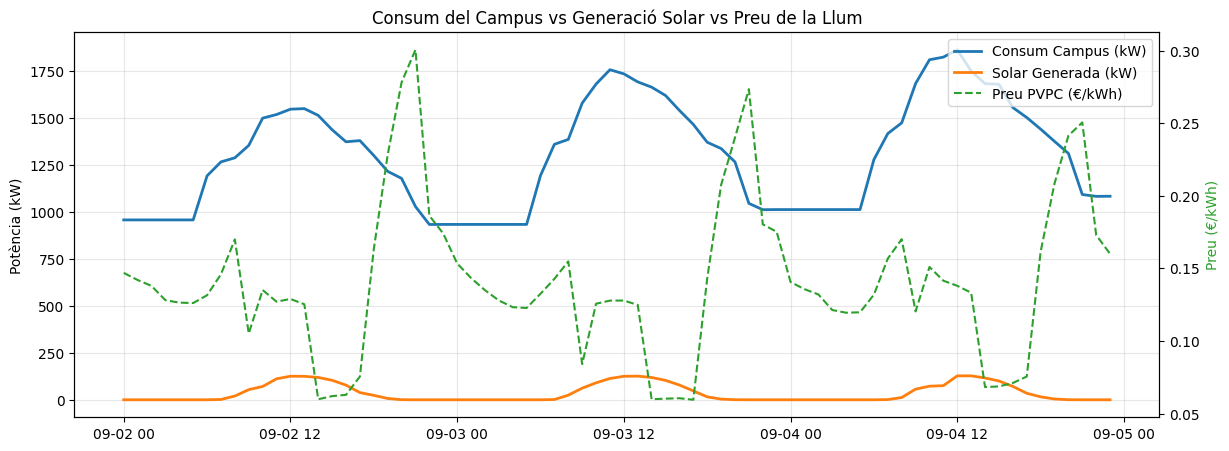

In [11]:
# Visualitzem 3 dies complets (72 hores)
sample_3days = df_campus_hourly.iloc[24:96]

fig, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(sample_3days.index, sample_3days["load_kw"], label="Consum Campus (kW)", color="tab:blue", lw=2)
ax1.plot(sample_3days.index, sample_3days["pv_kw"], label="Solar Generada (kW)", color="tab:orange", lw=2)
ax1.set_ylabel("Potència (kW)")
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(sample_3days.index, sample_3days["precio_eur_per_kwh"], label="Preu PVPC (€/kWh)", color="tab:green", ls="--")
ax2.set_ylabel("Preu (€/kWh)", color="tab:green")

plt.title("Consum del Campus vs Generació Solar vs Preu de la Llum")
fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.88))
plt.show()

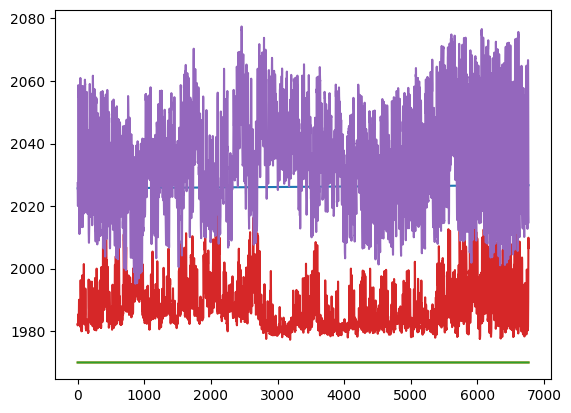

In [13]:
plt.plot(df_co2)

In [14]:
df_co2

,Fecha,co2_kg_per_kwh,porcentaje_con_emisiones,gen_con_emisiones_mw,gen_sin_emisiones_mw
0,2025-09-01 00:00:00,0.065316,0.176529,4490.5990,20947.6390
1,2025-09-01 01:00:00,0.065991,0.178355,4330.0765,19947.7815
2,2025-09-01 02:00:00,0.069553,0.187980,4426.3330,19120.5030
3,2025-09-01 03:00:00,0.071810,0.194081,4451.3075,18483.9595
4,2025-09-01 04:00:00,0.071963,0.194495,4423.0340,18318.0480
...,...,...,...,...,...
6763,2026-09-01 19:00:00,0.110538,0.298752,10880.7600,25539.9500
6764,2026-09-01 20:00:00,0.151145,0.408500,13740.6600,19896.1700
6765,2026-09-01 21:00:00,0.161807,0.437317,14568.0300,18744.2600
6766,2026-09-01 22:00:00,0.165930,0.448460,14034.4700,17260.3100


## 4. Simulació Seqüencial i Avaluació Local
Importem la classe `BatteryAgent` del fitxer `agent.py` i l'avaluem sobre les dades de validació:

In [6]:
from agent import BatteryAgent
from environment import run_agent_simulation

# Instanciem l'agent de control
agent = BatteryAgent()

# Executem la simulació sobre una setmana de prova (168 hores)
setmana_prova = df_campus_hourly.iloc[:168]
resultats = run_agent_simulation(agent, setmana_prova)

print("=== RESULTATS DE L'AVALUACIÓ ===")
for metric, val in resultats.items():
    print(f"  {metric:22s}: {val}")

=== RESULTATS DE L'AVALUACIÓ ===
  score                 : 2.16
  co2_estalviat_pct     : 1.86
  cost_estalviat_pct    : 2.86
  co2_estalviat_kg      : 241.0
  cost_estalviat_eur    : 672.75
  co2_participant_kg    : 12717.3
  cost_participant_eur  : 22871.37
  co2_baseline_kg       : 12958.2
  cost_baseline_eur     : 23544.12
  infraccions           : 0


## 5. Integració de Models d'Aprenentatge Automàtic (Scikit-Learn)
Si voleu predir la solar o el consum amb un model com Random Forest o XGBoost, el flux és molt senzill:
1. Entreneu el model amb les dades de Train.
2. El deseu amb `joblib.dump()`.
3. El carregueu a l'agent a `agent.py`.

In [9]:
from sklearn.ensemble import RandomForestRegressor
import joblib

# Exemple: Crear variables per predir la solar
X = pd.DataFrame({
    "hour": df_campus_hourly.index.hour,
    "dayofweek": df_campus_hourly.index.day_of_week
})
y = df_campus_hourly["pv_kw"]

X

,hour,dayofweek
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0
...,...,...
5988,18,6
5989,19,6
5990,20,6
5991,21,6


In [ ]:

model = RandomForestRegressor(n_estimators=50, random_state=42)
model.fit(X, y)

# Guardar el model entrenat:
joblib.dump(model, "model_solar_exemple.pkl")
print("Model guardat amb èxit a 'model_solar_exemple.pkl'!")

# Dins del vostre agent.py només heu de fer:
# from pathlib import Path
# self.model = joblib.load(Path(__file__).parent / 'model_solar_exemple.pkl')
# i cridar self.model.predict(...) dins de act(obs)

## 6. Comprovació local i generació del paquet de lliurament (`submission.zip`)

Abans de trametre la solució a la plataforma web de la UPC, podeu verificar-la en local amb el validador oficial `check_submission.py` i generar automàticament el paquet comprimit:


In [10]:
# 1. Validació tècnica local de l'agent (sense necessitat de xarxa ni navegador)
!python check_submission.py agent.py

# 2. Empaquetat net de la solució a submission.zip
import zipfile
from pathlib import Path

fitxers_a_empaquetar = ['agent.py']
for extra in ['model_solar.pkl', 'model_campus.pkl', 'parametres.json']:
    if Path(extra).exists():
        fitxers_a_empaquetar.append(extra)

with zipfile.ZipFile('submission.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for fitxer in fitxers_a_empaquetar:
        z.write(fitxer, fitxer)

print(f"Arxiu 'submission.zip' generat correctament amb: {fitxers_a_empaquetar}")


zsh:1: command not found: python
Arxiu 'submission.zip' generat correctament amb: ['agent.py']
